In [4]:
!pip install datasets evaluate transformers sentencepiece accelerate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 1.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 92.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 78.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 49.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 12.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 9.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 5.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 68.4 MB/s eta 0:00:00
  Attempting uninstall: nvidia-nvjitlink-cu12
    Found existing installation: nvidia-nvjitlink-cu12 12.5.82
    Uninstalling nvidia-nvjitlink-cu12-12.5.82:
      Successfully uninstalled nvidia-nvjitlin

In [1]:
import transformers
transformers.__version__

'4.52.3'

In [2]:
import evaluate
evaluate.__version__

'0.4.3'

In [3]:
import datasets
datasets.__version__

'2.14.4'

In [4]:
import accelerate
accelerate.__version__

'1.7.0'

### 1. Pipeline
The most basic object in the 🤗 Transformers library is the pipeline() function. We insert the pretrained model, and just use it for inference.

It connects a model with its necessary preprocessing and postprocessing steps, allowing us to directly input any text and get an intelligible answer. With pipeline, we can use already pretrained models off the shelf for inference.



In [7]:
from transformers import pipeline


classifier = pipeline(task="sentiment-analysis", model="distilbert-base-uncased-finetuned-sst-2-english")  # make sure the specified model supports specified task
classifier("I've been waiting for a HuggingFace course my whole life.")

config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

Device set to use cpu


[{'label': 'POSITIVE', 'score': 0.9598049521446228}]

In [8]:
classifier(["I do not love huggingface so much", "I've been waiting for a HuggingFace course my whole life.", "I don't hate it."]) # can pass multiple sentences as list

[{'label': 'NEGATIVE', 'score': 0.9867877960205078},
 {'label': 'POSITIVE', 'score': 0.9598049521446228},
 {'label': 'POSITIVE', 'score': 0.9947072267532349}]

By default, this pipeline selects a particular pretrained model that has been fine-tuned for sentiment analysis in English. The model is downloaded and cached when you create the classifier object. If you rerun the command, the cached model will be used instead and there is no need to download the model again.

There are three main steps involved when you pass some text to a pipeline:

- The text is preprocessed into a format the model can understand.
- The preprocessed inputs are passed to the model.
- The predictions of the model are post-processed, so you can make sense of them.

Some of the currently available pipelines NLP tasks are:

- feature-extraction (get the vector representation of a text)
- fill-mask (mask prediction)
- ner (named entity recognition)
- question-answering
- sentiment-analysis
- summarization
- text-generation
- text2text-generation
- translation
- zero-shot-classification
- document-question-answering
- image-to-text
- mask-generation
- token-classification
- table-question-answering

Note: For most pipeline tasks the parameters are explicitly listed in the documentation of the `__call__` method in documentation.

#### zero-shot-classification

In [9]:
from transformers import pipeline

clf = pipeline(task="zero-shot-classification")  # off the shelf classification on our data with our labels without finetuning with any our example data.
clf("This is about the Hugging face Transformers library", candidate_labels=["education", "politics", "business"])

# Note, zero shot classification model defaulted to facebook/bart-large-mnli

No model was supplied, defaulted to facebook/bart-large-mnli and revision d7645e1 (https://huggingface.co/facebook/bart-large-mnli).
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/1.15k [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.63G [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Device set to use cpu


{'sequence': 'This is about the Hugging face Transformers library',
 'labels': ['business', 'education', 'politics'],
 'scores': [0.42077335715293884, 0.3884904682636261, 0.19073618948459625]}

#### Text generation
The main idea here is that you provide a prompt and the model will auto-complete it by generating the remaining text.

In [11]:
from transformers import pipeline

generator = pipeline(task="text-generation", model="gpt2", max_length=30, pad_token_id=0)
generator("In this course, we will teach you how to")

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/548M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Device set to use cpu


[{'generated_text': "In this course, we will teach you how to create and edit your own templates.\n\nWhat's the difference between the different templates?\n\nThe templates in this course are written with the same language and syntax as the real project and should be"}]

The pipeline will use default model if model is not specified. Go to the Model Hub (https://huggingface.co/models) for full list.

Let’s try the distilgpt2 model! Here’s how to load it in the same pipeline as before:

In [15]:
from transformers import pipeline

generator = pipeline(task="text-generation", model="distilgpt2")  # knowledge distillation from gpt3 to gpt2
generator("In this course, we will teach you how to", truncation=True, max_new_tokens=30, max_length=30, pad_token_id=0, num_return_sequences=2)

Device set to use cpu
Both `max_new_tokens` (=30) and `max_length`(=30) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[{'generated_text': 'In this course, we will teach you how to use these tools and learn how to use them in your environment.!!!!!!!!!!!!!!!!'},
 {'generated_text': 'In this course, we will teach you how to apply an S-L-G-A-L-E-L-G-A-L-E-L-G-A-'}]

#### Mask Prediction

In [17]:
from transformers import pipeline

unmasker = pipeline(task="fill-mask", model="distilroberta-base")  # base is the first base model and form then large, small models ll be available

# The top_k argument controls how many possibilities you want to be displayed.
unmasker("This course will teach you all about <mask> models.", top_k=2)

Some weights of the model checkpoint at distilroberta-base were not used when initializing RobertaForMaskedLM: ['roberta.pooler.dense.bias', 'roberta.pooler.dense.weight']
- This IS expected if you are initializing RobertaForMaskedLM from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing RobertaForMaskedLM from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).
Device set to use cpu


[{'score': 0.19619767367839813,
  'token': 30412,
  'token_str': ' mathematical',
  'sequence': 'This course will teach you all about mathematical models.'},
 {'score': 0.04052715748548508,
  'token': 38163,
  'token_str': ' computational',
  'sequence': 'This course will teach you all about computational models.'}]

### Named entity recognition

In [18]:
from transformers import pipeline

ner = pipeline(task="ner", aggregation_strategy="simple", model="dbmdz/bert-large-cased-finetuned-conll03-english")  # base is the first base model and form then large, small models ll be available

# The top_k argument controls how many possibilities you want to be displayed.
ner("My name is Bhavana and I work at Hugging Face in Brooklyn.")

config.json:   0%|          | 0.00/998 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.33G [00:00<?, ?B/s]

Some weights of the model checkpoint at dbmdz/bert-large-cased-finetuned-conll03-english were not used when initializing BertForTokenClassification: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight']
- This IS expected if you are initializing BertForTokenClassification from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing BertForTokenClassification from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


tokenizer_config.json:   0%|          | 0.00/60.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

Device set to use cpu


[{'entity_group': 'PER',
  'score': np.float32(0.979492),
  'word': 'Bhavana',
  'start': 11,
  'end': 18},
 {'entity_group': 'ORG',
  'score': np.float32(0.98459315),
  'word': 'Hugging Face',
  'start': 33,
  'end': 45},
 {'entity_group': 'LOC',
  'score': np.float32(0.99221003),
  'word': 'Brooklyn',
  'start': 49,
  'end': 57}]

`aggregation_strategy="simple"` tell the pipeline to regroup together the parts of the sentence that correspond to the same entity.

For eg, here the model correctly grouped “Hugging” and “Face” as a single organization, even though the name consists of multiple words.

#### Question Answering

In [19]:
from transformers import pipeline

qa = pipeline("question-answering", model="distilbert-base-cased-distilled-squad")

qa(question="Where do I work?", context="My name is Bhavana and I work at Hugging Face in Brooklyn.")

config.json:   0%|          | 0.00/473 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/261M [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/436k [00:00<?, ?B/s]

Device set to use cpu


{'score': 0.6834427714347839, 'start': 33, 'end': 45, 'answer': 'Hugging Face'}

#### Summarization

In [20]:
from transformers import pipeline

summarizer = pipeline("summarization", model="sshleifer/distilbart-cnn-12-6", max_length=100)

summarizer(
    """
    America has changed dramatically during recent years. Not only has the number of
    graduates in traditional engineering disciplines such as mechanical, civil,
    electrical, chemical, and aeronautical engineering declined, but in most of
    the premier American universities engineering curricula now concentrate on
    and encourage largely the study of engineering science. As a result, there
    are declining offerings in engineering subjects dealing with infrastructure,
    the environment, and related issues, and greater concentration on high
    technology subjects, largely supporting increasingly complex scientific
    developments. While the latter is important, it should not be at the expense
    of more traditional engineering.

    Rapidly developing economies such as China and India, as well as other
    industrial countries in Europe and Asia, continue to encourage and advance
    the teaching of engineering. Both China and India, respectively, graduate
    six and eight times as many traditional engineers as does the United States.
    Other industrial countries at minimum maintain their output, while America
    suffers an increasingly serious decline in the number of engineering graduates
    and a lack of well-educated engineers.
    """
)

config.json:   0%|          | 0.00/1.80k [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/1.22G [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.22G [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

Device set to use cpu


[{'summary_text': ' America has changed dramatically during recent years . The number of engineering graduates in the U.S. has declined in traditional engineering disciplines such as mechanical, civil, electrical, chemical, and aeronautical engineering . Rapidly developing economies such as China and India, as well as other industrial countries in Europe and Asia, continue to encourage and advance engineering .'}]

#### Translation

In [21]:
from transformers import pipeline

translator = pipeline("translation", model="Helsinki-NLP/opus-mt-fr-en")

translator("Ce cours est produit par Hugging Face.")

config.json:   0%|          | 0.00/1.42k [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/301M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/293 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/42.0 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/301M [00:00<?, ?B/s]

source.spm:   0%|          | 0.00/802k [00:00<?, ?B/s]

target.spm:   0%|          | 0.00/778k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.34M [00:00<?, ?B/s]

/usr/local/lib/python3.11/dist-packages/transformers/models/marian/tokenization_marian.py:177: UserWarning: Recommended: pip install sacremoses.
  warnings.warn("Recommended: pip install sacremoses.")
Device set to use cpu


[{'translation_text': 'This course is produced by Hugging Face.'}]

### 2. A bit about transformers

This is the short history of transformers:

- June 2018: GPT, the first pretrained Transformer model, used for fine-tuning on various NLP tasks and obtained state-of-the-art results
- October 2018: BERT, another large pretrained model, this one designed to produce better summaries of sentences (more on this in the next chapter!)
- February 2019: GPT-2, an improved (and bigger) version of GPT that was not immediately publicly released due to ethical concerns
- October 2019: DistilBERT, a distilled version of BERT that is 60% faster, 40% lighter in memory, and still retains 97% of BERT’s performance
- October 2019: BART and T5, two large pretrained models using the same architecture as the original Transformer model (the first to do so)
- May 2020, GPT-3, an even bigger version of GPT-2 that is able to perform well on a variety of tasks without the need for fine-tuning (called zero-shot learning)

This list is far from comprehensive, and is just meant to highlight a few of the different kinds of Transformer models. Broadly, they can be grouped into three categories:

- BERT-like (also called auto-encoding or encoder Transformer models)
- GPT-like (also called auto-regressive or decoder Transformer models)
- BART/T5-like (also called sequence-to-sequence or encoder-decoder Transformer models)

**Encoder**

Encoder models use only the encoder of a Transformer model. The pretraining of these models usually revolves around masked language modeling.(self-supervised)

Encoder models are best suited for tasks requiring an understanding of the full sentence, such as sentence classification, named entity recognition (and more generally word classification), and extractive question answering.

Representatives of this family of models include: ALBERT, BERT, DistilBERT, ELECTRA, RoBERTa

**Decoder**

Decoder models use only the decoder of a Transformer model. The pretraining of decoder models usually revolves around predicting the next word in the sentence.(self-supervised)

These models are best suited for tasks involving text generation.

Representatives of this family of models include: CTRL, GPT, GPT-2, Transformer XL

**Encoder-decoder**

Encoder-decoder models (also called sequence-to-sequence models) use both parts of the Transformer architecture.

The pretraining of these models can be done using the objectives of encoder or decoder models, but usually involves something a bit more complex. For instance, T5 is pretrained by replacing random spans of text (that can contain several words) with a single mask special word, and the objective is then to predict the text that this mask word replaces.

Sequence-to-sequence models are best suited for tasks revolving around generating new sentences depending on a given input, such as summarization, translation, or generative question answering.

Representatives of this family of models include: BART, mBART, Marian, T5

**Transformers are language models**

All the Transformer models mentioned above (GPT, BERT, BART, T5, etc.) have been trained as language models. This means they have been trained on large amounts of raw text in a self-supervised fashion.

This type of model develops a **statistical understanding of the language** it has been trained on (also called pretraining), but it’s not very useful for specific practical tasks. Because of this, the general pretrained model then goes through a process called **transfer learning or finetuning**. During this process, the model is fine-tuned in a supervised way — that is, using human-annotated labels — on a given task.

Note that finetuning is almost always better than training from scratch. Since the pretrained model already contains many basic statistical understanding of langauge, thus finetuning requires less resource and time to train.



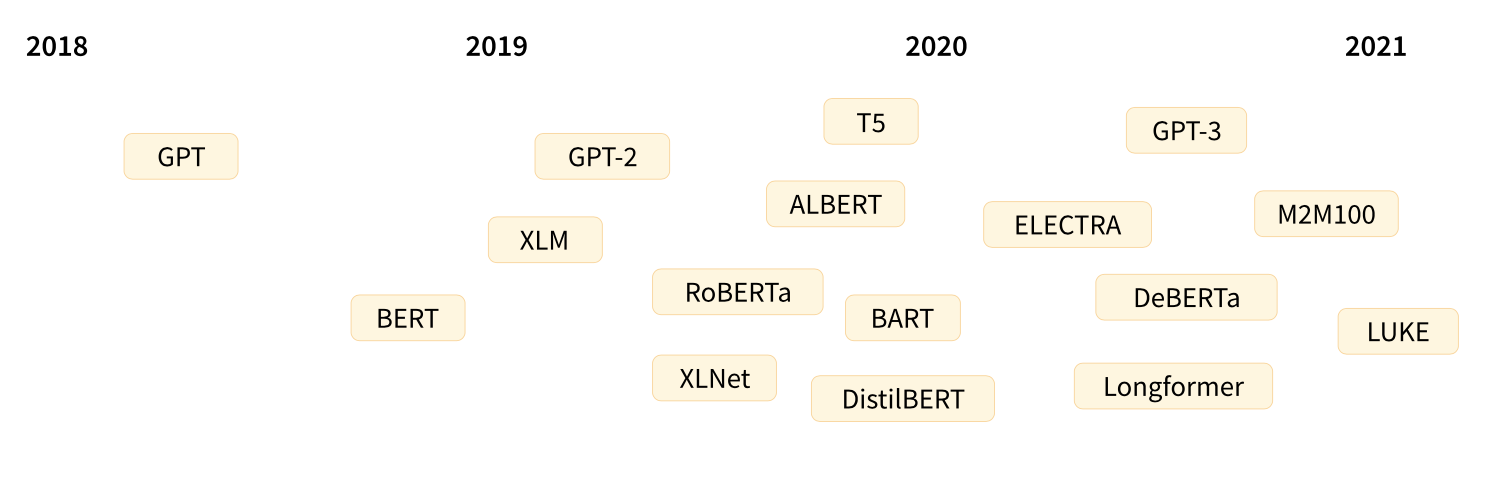

### 3. Bias and Limitations
Since pretrained model is trained on real-world datasets, it can unintentionally grab human biases. For example:

In [22]:
from transformers import pipeline

unmasker = pipeline("fill-mask", model='distilroberta-base')
result = unmasker("This man works as a <mask>.")
print([r["token_str"] for r in result])

result = unmasker("This woman works as a <mask>.")
print([r["token_str"] for r in result])

Some weights of the model checkpoint at distilroberta-base were not used when initializing RobertaForMaskedLM: ['roberta.pooler.dense.bias', 'roberta.pooler.dense.weight']
- This IS expected if you are initializing RobertaForMaskedLM from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing RobertaForMaskedLM from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).
Device set to use cpu


[' translator', ' consultant', ' bartender', ' waiter', ' courier']
[' waitress', ' translator', ' nurse', ' bartender', ' consultant']


### 4. Behind the pipeline
Let’s take a look at what happened behind the pipeline, so we can make our own what is more useful.

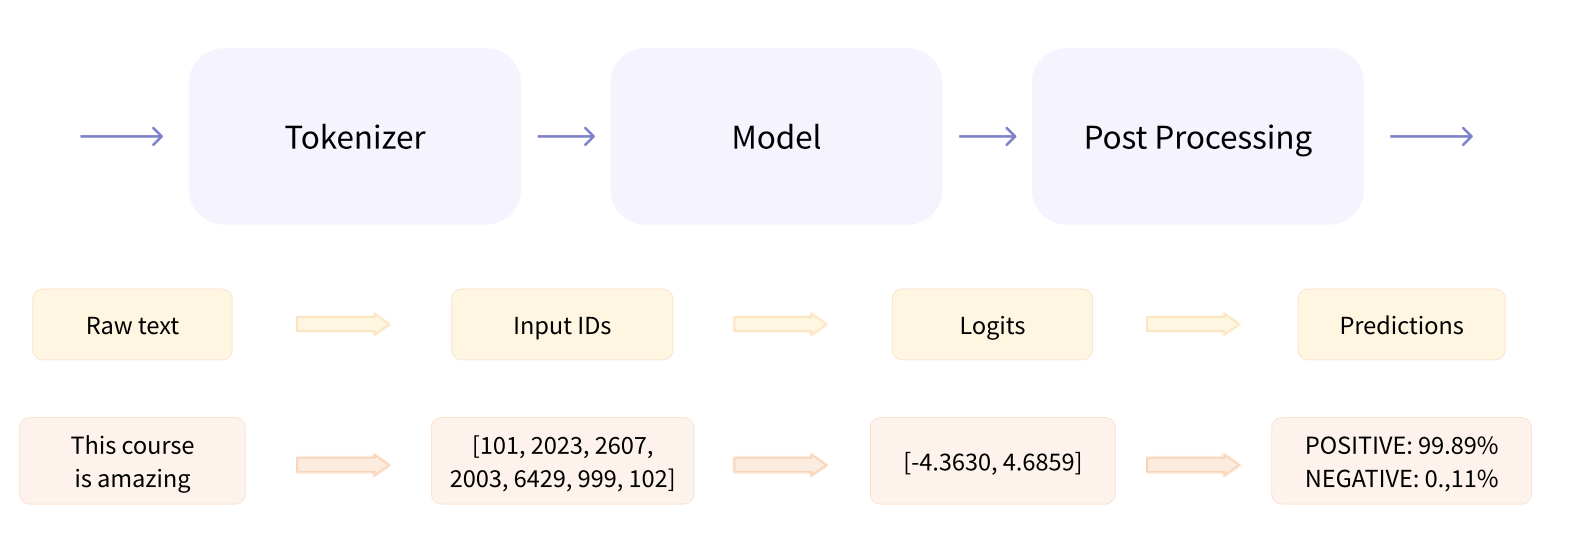

In [23]:
from transformers import pipeline

classifier = pipeline("sentiment-analysis", model='distilbert-base-uncased-finetuned-sst-2-english')
classifier(
    [
        "I've been waiting for a HuggingFace course my whole life.",
        "I hate this so much!",
    ]
)

Device set to use cpu


[{'label': 'POSITIVE', 'score': 0.9598049521446228},
 {'label': 'NEGATIVE', 'score': 0.9994558691978455}]

#### 4.1. Tokenizer

Steps of Tokenizer
--------------------

- Splitting the input into words, subwords, or symbols (like punctuation) that are called tokens
- Mapping each token to an integer
- Adding additional special inputs that may be useful to the model

Our pipeline does this automatically based on the given or default model tokenizer. We can do the same or use our required tokenization process without using pipeline.

To do this, we use the `AutoTokenizer` class and its `from_pretrained()` method. Using the checkpoint name of our model, it will automatically fetch the data associated with the model’s tokenizer and cache it (so it’s only downloaded the first time you run the code below).

Since the default checkpoint of the `sentiment-analysis` pipeline is distilbert-base-uncased-finetuned-sst-2-english, we run the following:

In [24]:
from transformers import AutoTokenizer

checkpoint = "distilbert-base-uncased-finetuned-sst-2-english"
tokenizer = AutoTokenizer.from_pretrained(checkpoint)

Once we have the tokenizer, we can directly pass our sentences to it and we’ll get back a dictionary that’s ready to feed to our model! The only thing left to do is to convert the list of input IDs to tensors.

To specify the type of tensors we want to get back (PyTorch, TensorFlow, or plain NumPy), we use the `return_tensors` argument

In [27]:
raw_inputs = [
    "I've been waiting for a HuggingFace course my whole life.",
    "I hate waiting!",
]

inputs = tokenizer(raw_inputs, padding=True, truncation=True, return_tensors="pt") # pt for returning pytorch tensors and tf for tensorflow tensor

inputs

{'input_ids': tensor([[  101,  1045,  1005,  2310,  2042,  3403,  2005,  1037, 17662, 12172,
          2607,  2026,  2878,  2166,  1012,   102],
        [  101,  1045,  5223,  3403,   999,   102,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0]]), 'attention_mask': tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]])}

It returns input_ids with padding tokens, attention_mask to know which tokens to apply self attention to for this selected tokenizer

In [29]:
tokenizer.decode(inputs["input_ids"][0])  # we can get the actual word mappings using decode function. Note the CLS and SEP token appened to input(BERT)

"[CLS] i've been waiting for a huggingface course my whole life. [SEP]"

In [31]:
tokenizer.decode([101,  1045,  5223,  3403,   999,   102,     0,     0,     0,     0,
                  0,     0,     0,     0,     0,     0])  # see the pad token applied to have same seq length

'[CLS] i hate waiting! [SEP] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD]'

#### 4.2. Model

The second component of Pipeline (after Tokenizer). Similarly we can use the abstract class called `AutoModel` to customize the model as we need.

We can download our pretrained model the same way we did with our tokenizer. Transformers provides an AutoModel class which also has a from_pretrained() method.

This architecture contains only the base Transformer module: given some inputs, it outputs what we’ll call hidden states, also known as features. For each model input, we’ll retrieve a high-dimensional vector representing the contextual understanding of that input by the Transformer model.

While these hidden states can be useful on their own, they’re usually inputs to another part of the model, known as the head.

In [33]:
from transformers import AutoModel

checkpoint = "distilbert-base-uncased-finetuned-sst-2-english"
model = AutoModel.from_pretrained(checkpoint)

In [34]:
inputs

{'input_ids': tensor([[  101,  1045,  1005,  2310,  2042,  3403,  2005,  1037, 17662, 12172,
          2607,  2026,  2878,  2166,  1012,   102],
        [  101,  1045,  5223,  3403,   999,   102,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0]]), 'attention_mask': tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]])}

In [36]:
outputs = model(**inputs)  # ** to tell we are passing kwargs , * to tell we are passing args or list or tuples in python

The vector output by the Transformer module is usually large. It generally has three dimensions:

- Batch size: The number of sequences processed at a time (2 in our example).
- Sequence length: The length of the numerical representation of the sequence (16 in our example).
- Hidden size: The vector dimension of each model input.

In [37]:
outputs # return logits from last hidden state of transformer (bs, max_seq_len, hidden_dim)

BaseModelOutput(last_hidden_state=tensor([[[-0.1798,  0.2333,  0.6321,  ..., -0.3017,  0.5008,  0.1481],
         [ 0.2758,  0.6497,  0.3200,  ..., -0.0760,  0.5136,  0.1329],
         [ 0.9046,  0.0985,  0.2950,  ...,  0.3352, -0.1407, -0.6464],
         ...,
         [ 0.1466,  0.5661,  0.3235,  ..., -0.3376,  0.5100, -0.0561],
         [ 0.7500,  0.0487,  0.1738,  ...,  0.4684,  0.0030, -0.6084],
         [ 0.0519,  0.3729,  0.5223,  ...,  0.3584,  0.6500, -0.3883]],

        [[-0.0436,  0.5894, -0.2005,  ..., -0.5374, -0.5565,  0.1572],
         [-0.0718,  0.7953, -0.0761,  ..., -0.5076, -0.2330,  0.6001],
         [ 0.0215,  0.8494,  0.0244,  ..., -0.3533, -0.3299,  0.4516],
         ...,
         [-0.1301,  0.6484, -0.0930,  ..., -0.3648, -0.4303, -0.0069],
         [-0.0472,  0.6924,  0.0243,  ..., -0.3948, -0.4947,  0.0141],
         [-0.0972,  0.6495, -0.0980,  ..., -0.3180, -0.4251, -0.0249]]],
       grad_fn=<NativeLayerNormBackward0>), hidden_states=None, attentions=None)

In [38]:
outputs.last_hidden_state.shape

torch.Size([2, 16, 768])

##### Model heads: Making sense out of numbers

The model heads take the high-dimensional vector of hidden states as input and project them onto a different dimension. They are usually composed of one or a few linear layers:


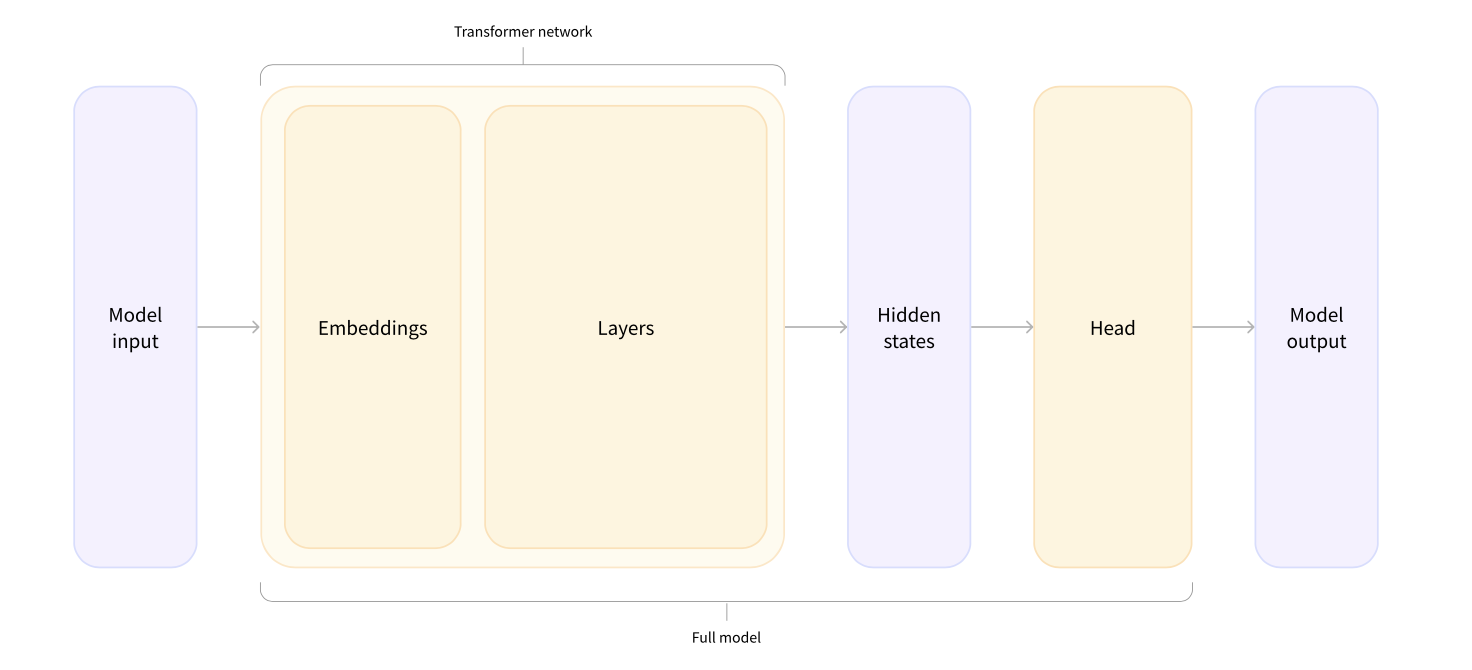

The output of the Transformer model is sent directly to the model head to be processed.

In this diagram, the model is represented by its embeddings layer and the subsequent layers. The embeddings layer converts each input ID in the tokenized input into a vector that represents the associated token. The subsequent layers manipulate those vectors using the attention mechanism to produce the final representation of the sentences.

There are many different architectures available, with each one designed around tackling a specific task. Here is a non-exhaustive list:

- Model (retrieve the hidden states)
- ForCausalLM
- ForMaskedLM
- ForMultipleChoice
- ForQuestionAnswering
- ForSequenceClassification
- ForTokenClassification

For our example, we will need a model with a sequence classification head (to be able to classify the sentences as positive or negative). So, we won’t actually use the `AutoModel` class, but `AutoModelForSequenceClassification`

#### 4.3 Postprocessing

Last step of the Pipeline (after the Model) to get the logits required for our task and then to softmax and then to prediction.

Here we use `AutoModelForSequenceClassification`. Imagine this model as a head model => transformer model + final feed-forward head on top to get the logits of predefined class labels. So Instead of AutoModel, this class applied AutoModel step and also the feedfoward step. Note we are passing inputs to this model to do the whole process.

`AutoModelForSequenceClassification` based on the given model checkpoint decides the class labels. Here we are giving sentiment analysis model that has labels Positive or Negative(polarity).

In [39]:
from transformers import AutoModelForSequenceClassification

checkpoint = "distilbert-base-uncased-finetuned-sst-2-english"

model = AutoModelForSequenceClassification.from_pretrained(checkpoint)

outputs = model(**inputs)

outputs

SequenceClassifierOutput(loss=None, logits=tensor([[-1.5607,  1.6123],
        [ 2.8984, -2.4341]], grad_fn=<AddmmBackward0>), hidden_states=None, attentions=None)

Now if we look at the shape of our outputs, the dimensionality will be much lower: the model head takes as input the high-dimensional vectors we saw before, and outputs vectors containing two values (one per label):

Our model predicted [-1.5607, 1.6123] for the first sentence and [ 2.8984, -2.4341] for the second one. Those are not probabilities but logits, the raw, unnormalized scores outputted by the last layer of the model. To be converted to probabilities, they need to go through a SoftMax layer (all Transformers models output the logits, as the loss function for training will generally fuse the last activation function, such as SoftMax, with the actual loss function, such as cross entropy)

In [40]:
outputs.logits.shape  # bs, num_classes

torch.Size([2, 2])

To get the labels corresponding to each position, we can inspect the id2label attribute of the model config.

In [41]:
# we can access mapping from model's config

model.config.id2label

{0: 'NEGATIVE', 1: 'POSITIVE'}

In [42]:
# prob distribution
import torch

probs = torch.nn.functional.softmax(outputs.logits, dim=1)
probs  # negative label score, positive label score for each seq in the batch (2, 2)

tensor([[0.0402, 0.9598],
        [0.9952, 0.0048]], grad_fn=<SoftmaxBackward0>)

Now we can see that the model predicted [0.0402, 0.9598] for the first sentence and [0.9952, 0.0048] for the second one. These are recognizable probability scores.

Now we can conclude that the model predicted the following:

First sentence: NEGATIVE: 0.0402, POSITIVE: 0.9598 Second sentence: NEGATIVE: 0.9952, POSITIVE: 0.0048